<a href="https://colab.research.google.com/github/yousefkoriem/Computer-Vision-Lab/blob/main/CNN%2BTF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import keras

In [2]:
cf10 = keras.datasets.cifar10
(x_train, y_train), (x_test, y_test) = cf10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1101s 6us/step


In [3]:
model = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Rescaling(1./255.0),
    keras.layers.Conv2D(32, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

In [4]:
checkpoint = keras.callbacks.ModelCheckpoint('best_model.keras', save_best_only=True, monitor='val_accuracy', mode='max')
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)
lr_scheduler = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=2)

In [5]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history1 = model.fit(x_train, y_train, epochs=128, validation_split=0.2,batch_size=128,callbacks=[checkpoint, early_stopping, lr_scheduler])

Epoch 1/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 41ms/step - accuracy: 0.3654 - loss: 1.7257 - val_accuracy: 0.4456 - val_loss: 1.5157 - learning_rate: 0.0010
Epoch 2/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5017 - loss: 1.3844 - val_accuracy: 0.5406 - val_loss: 1.3005 - learning_rate: 0.0010
Epoch 3/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5626 - loss: 1.2352 - val_accuracy: 0.5828 - val_loss: 1.1863 - learning_rate: 0.0010
Epoch 4/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6040 - loss: 1.1261 - val_accuracy: 0.6040 - val_loss: 1.1444 - learning_rate: 0.0010
Epoch 5/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6336 - loss: 1.0458 - val_accuracy: 0.6382 - val_loss: 1.0469 - learning_rate: 0.0010
Epoch 6/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6566 - loss: 0.9836 - val_accuracy: 0.6439 - val_loss: 1.0099 - learning_rate: 0.0010
Epoch 7/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6748 - loss: 

In [8]:
train_loss, train_acc = model.evaluate(x_train, y_train)
test_loss, test_acc = model.evaluate(x_test, y_test)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8154 - loss: 0.5506
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7248 - loss: 0.8329


In [9]:
train_loss, train_acc

(0.5506450533866882, 0.8154399991035461)

In [10]:
test_loss, test_acc

(0.8328931927680969, 0.7247999906539917)

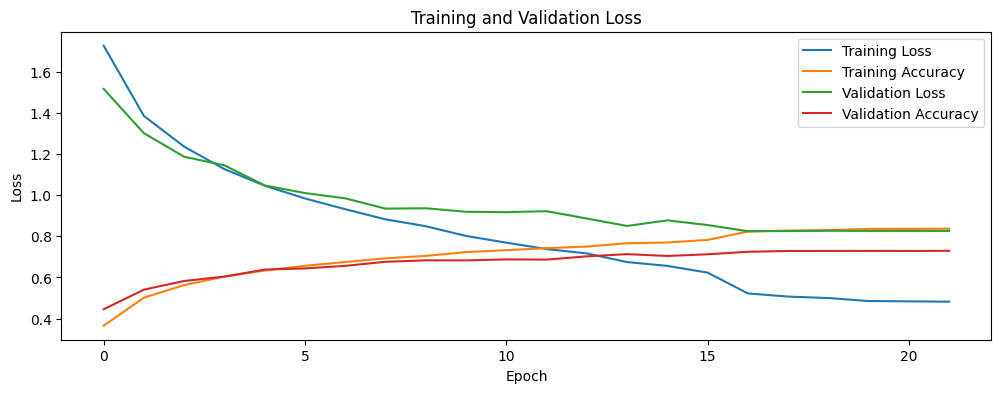

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
sns.lineplot(data=history1.history['loss'], label='Training Loss')
sns.lineplot(data=history1.history['accuracy'], label='Training Accuracy')
sns.lineplot(data=history1.history['val_loss'], label='Validation Loss')
sns.lineplot(data=history1.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

### Pretrained Models

In [12]:
base_model = keras.applications.ResNet152V2(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
)
base_model.trainable = False

234545216/234545216 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [13]:
inputs = keras.layers.Input(shape=(32, 32, 3))
x = keras.layers.Resizing(224, 224, interpolation="bilinear")(inputs)
x = keras.applications.resnet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(512, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-3))(x)
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)

model2 = keras.models.Model(inputs, outputs)
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [14]:
history2 = model2.fit(x_train, y_train, epochs=128, validation_split=0.2,batch_size=128,callbacks=[checkpoint, early_stopping, lr_scheduler])

Epoch 1/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 452s 1s/step - accuracy: 0.8619 - loss: 0.8797 - val_accuracy: 0.8850 - val_loss: 0.6320 - learning_rate: 0.0010
Epoch 2/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 348s 1s/step - accuracy: 0.8981 - loss: 0.5326 - val_accuracy: 0.9019 - val_loss: 0.4831 - learning_rate: 0.0010
Epoch 3/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 345s 1s/step - accuracy: 0.9063 - loss: 0.4492 - val_accuracy: 0.8999 - val_loss: 0.4601 - learning_rate: 0.0010
Epoch 4/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 344s 1s/step - accuracy: 0.9078 - loss: 0.4203 - val_accuracy: 0.8924 - val_loss: 0.4761 - learning_rate: 0.0010
Epoch 5/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 340s 1s/step - accuracy: 0.9111 - loss: 0.4038 - val_accuracy: 0.8815 - val_loss: 0.4935 - learning_rate: 0.0010
Epoch 6/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 341s 1s/step - accuracy: 0.9375 - loss: 0.3232 - val_accuracy: 0.9127 - val_loss: 0.3956 - learning_rate: 1.0000e-04
Epoch 7/128
313/313 ━━━━━━━━━━━━━━━━━━━━ 341s 1s/step - accuracy: 0.9451

In [15]:
train_loss, train_acc = model2.evaluate(x_train, y_train)
test_loss, test_acc = model2.evaluate(x_test, y_test)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 374s 226ms/step - accuracy: 0.9777 - loss: 0.1626
313/313 ━━━━━━━━━━━━━━━━━━━━ 70s 224ms/step - accuracy: 0.9099 - loss: 0.3395


In [16]:
train_loss, train_acc

(0.1625758558511734, 0.9776999950408936)

In [17]:
test_loss, test_acc

(0.33948174118995667, 0.9099000096321106)

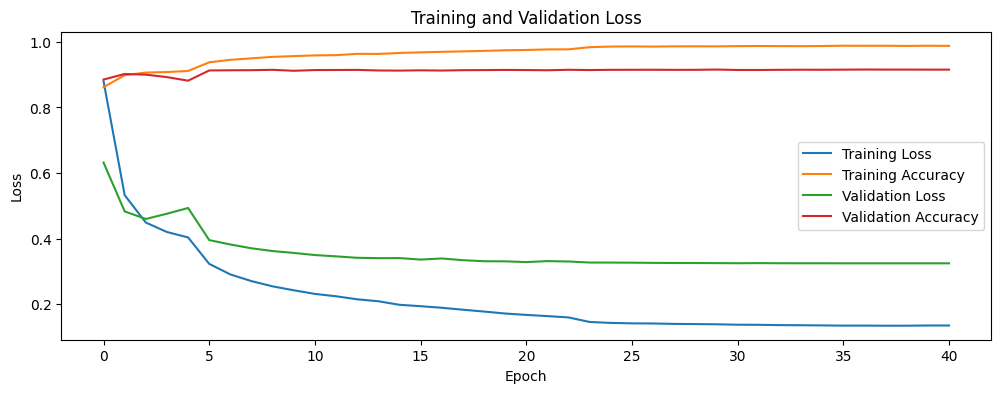

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
sns.lineplot(data=history2.history['loss'], label='Training Loss')
sns.lineplot(data=history2.history['accuracy'], label='Training Accuracy')
sns.lineplot(data=history2.history['val_loss'], label='Validation Loss')
sns.lineplot(data=history2.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

In [19]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU is available: {gpus}")
    # Display details about the available GPU
    !nvidia-smi
else:
    print("No GPU detected. TensorFlow is running on the CPU. To enable GPU, go to Runtime -> Change runtime type -> select T4 GPU.")

GPU is available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Wed Nov 25 01:56:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P0             34W /   70W |    4225MiB /  15360MiB |      0%      Default |
|                                         |            